# Notebook 10 – Feature Selection

# 1. What is Feature Selection?


## Step 1 – Understand Concept

Feature Selection is the process of selecting useful input features from a dataset for Machine Learning.

Features are the columns used by a model to make predictions.

For example, a customer churn dataset may contain:
- Tenure
- MonthlyCharges
- Contract
- InternetService
- CustomerID

Some features may help predict churn, while others may be irrelevant or redundant.

Feature selection identifies useful features and removes unnecessary ones when justified.

The goal is to build a simpler, more efficient, and potentially more accurate model.

Feature selection is different from feature extraction. Selection keeps chosen original features, while extraction creates new representations from existing features.



## Step 2 – Demonstrate Concept

Suppose we want to predict whether a customer will leave a telecom company.

Useful candidate features:
- Tenure
- MonthlyCharges
- Contract
- PaymentMethod

Potentially unnecessary feature:
- CustomerID, if it is only an identifier with no meaningful predictive information.

If we include every column without investigation, the model may learn unhelpful patterns.

Feature selection helps us focus on informative inputs.



## Step 3 – Implement the Concept

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({
    "Tenure": [2, 5, 12, 24, 36, 48],
    "MonthlyCharges": [80, 75, 70, 65, 60, 55],
    "ContractMonths": [1, 1, 12, 12, 24, 24],
    "CustomerID": [1001, 1002, 1003, 1004, 1005, 1006],
    "Churn": [1, 1, 1, 0, 0, 0]
})

X = df.drop(columns="Churn")
y = df["Churn"]

print("Available features:", list(X.columns))
print("Target:", y.name)
print("Dataset shape:", X.shape)

Available features: ['Tenure', 'MonthlyCharges', 'ContractMonths', 'CustomerID']
Target: Churn
Dataset shape: (6, 4)


## Result / Observation

The dataset contains four candidate input features and one target column.

Feature selection investigates which inputs are useful for predicting Churn.

CustomerID should not automatically be removed in every possible dataset, but a unique identifier usually has no generalizable predictive meaning.

# 2. Why Feature Selection?


## Step 1 – Understand Concept

Feature selection can provide several benefits:

1. Reduce unnecessary input columns.
2. Reduce model training time.
3. Reduce memory usage.
4. Improve interpretability.
5. Reduce noise and overfitting in some situations.
6. Make it easier to understand which features matter.
7. Reduce the cost of collecting or maintaining features.

However, removing useful features can reduce predictive performance.

Feature selection should be based on evidence, domain knowledge, and model evaluation rather than simply trying to keep the fewest columns.



## Step 2 – Demonstrate Concept

Imagine a dataset with 500 input features, but only 25 contain useful information.

Using all 500 features may increase computation and introduce noise.

Selecting a smaller, informative set can simplify the model.

However, a feature that appears weak on its own may still be useful when combined with other features.



## Step 3 – Implement the Concept

In [2]:
# Example of reducing the number of candidate features

selected_features = [
    "Tenure",
    "MonthlyCharges",
    "ContractMonths"
]

X_selected = X[selected_features]

print("Original feature count:", X.shape[1])
print("Selected feature count:", X_selected.shape[1])
print("Selected columns:", list(X_selected.columns))

Original feature count: 4
Selected feature count: 3
Selected columns: ['Tenure', 'MonthlyCharges', 'ContractMonths']


## Result / Observation

The number of input features decreased from four to three.

This demonstrates feature reduction, but it does not prove that the selected features produce a better model.

To evaluate the benefit, compare models using the same train/test split and appropriate metrics.

# 3. Relevant Features


## Step 1 – Understand Concept

Relevant features contain useful information for predicting the target variable.

Their usefulness depends on the prediction problem.

For customer churn, tenure, contract type, monthly charges, and service usage may contain predictive information.

A relevant feature may have:
- A meaningful relationship with the target.
- Useful information in combination with other features.
- Business meaning related to the prediction task.

A feature's relevance must be assessed using training data and appropriate validation.



## Step 2 – Demonstrate Concept

For churn prediction:

Tenure may be relevant because customer retention patterns can differ with customer tenure.

Contract type may be relevant because customers on different contracts may have different churn behaviour.

However, relevance cannot be assumed only from an example. It should be checked using the actual dataset and a valid evaluation process.



## Step 3 – Implement the Concept

In [3]:
# Illustrative example: compare average tenure by churn class

print(
    df.groupby("Churn")["Tenure"]
      .mean()
      .rename({
          0: "Stayed",
          1: "Churned"
      })
)

Churn
Stayed     36.000000
Churned     6.333333
Name: Tenure, dtype: float64


## Result / Observation

The group averages show whether tenure differs between the two churn classes in this small example.

A difference suggests a possible relationship, but it does not prove that tenure alone can predict churn accurately.

Use a larger dataset and model evaluation before making a feature-selection decision.

# 4. Irrelevant Features


## Step 1 – Understand Concept

An irrelevant feature provides little or no useful information for the prediction task.

Examples may include:
- A randomly generated column.
- A record number with no predictive meaning.
- A constant column.
- A column unrelated to the target.

Some identifiers can accidentally correlate with the target because of how the dataset was collected. That does not necessarily mean they will generalize to new data.

A feature should be removed only after checking its meaning and usefulness.



## Step 2 – Demonstrate Concept

Suppose a dataset includes:

Tenure
MonthlyCharges
ContractMonths
RandomNumber

If RandomNumber was generated independently of customer behaviour, it should not provide useful generalizable information about churn.

Keeping it adds an unnecessary input without a meaningful predictive reason.



## Step 3 – Implement the Concept

In [4]:
np.random.seed(42)

df["RandomNumber"] = np.random.randint(
    1000, 9999, size=len(df)
)

X_with_noise = df.drop(columns="Churn")

print(X_with_noise.head())

   Tenure  MonthlyCharges  ContractMonths  CustomerID  RandomNumber
0       2              80               1        1001          8270
1       5              75               1        1002          1860
2      12              70              12        1003          6390
3      24              65              12        1004          6191
4      36              60              24        1005          6734


## Result / Observation

RandomNumber was added only for demonstration.

It has no intended business relationship with churn.

In a real dataset, investigate a feature's meaning and behaviour before removing it. Random-looking values alone do not always prove that a feature is useless.

# 5. Redundant Features


## Step 1 – Understand Concept

Redundant features contain information that overlaps substantially with other features.

For example:
- Monthly salary and annual salary may convey the same information.
- Distance in kilometres and distance in metres are directly related.
- Two columns may be nearly identical.

Redundant features can increase complexity and make some models harder to interpret.

However, correlated features are not always useless. They may still provide value, and removing them should depend on the model and task.


## Step 2 – Demonstrate Concept

Suppose a dataset contains:

MonthlySalary = 30,000
AnnualSalary = 360,000

If AnnualSalary is always exactly 12 times MonthlySalary, both features carry the same underlying information.

Keeping both may be unnecessary for some models.

A feature-selection decision should also consider whether the two columns use different definitions or contain different kinds of information in the real dataset.



## Step 3 – Implement the Concept

In [5]:
salary_df = pd.DataFrame({
    "MonthlySalary": [20000, 30000, 40000, 50000],
    "AnnualSalary": [240000, 360000, 480000, 600000]
})

print(
    salary_df.corr(numeric_only=True)
)

               MonthlySalary  AnnualSalary
MonthlySalary            1.0           1.0
AnnualSalary             1.0           1.0


## Result / Observation

The two features have a perfect positive linear correlation because AnnualSalary is calculated directly from MonthlySalary.

They contain the same underlying information in this example.

Depending on the model and business requirements, one feature may be sufficient.

# 6. Correlation-Based Selection


## Step 1 – Understand Concept

Correlation measures the strength and direction of a linear relationship between two numerical variables.

Pearson correlation ranges from -1 to +1.

+1: perfect positive linear relationship
-1: perfect negative linear relationship
 0: no linear relationship

Correlation-based feature selection can identify:
- Features strongly related to a numerical target.
- Pairs of highly correlated input features.

Important limitations:
- Correlation does not prove causation.
- A low Pearson correlation does not rule out a nonlinear relationship.
- Categorical features may require different methods.
- Correlation with the target alone does not establish that a feature is useful in a predictive model.



## Step 2 – Demonstrate Concept

If two features have a correlation of 0.98, they may carry very similar linear information.

We can investigate whether both are needed.

If a feature has a weak linear correlation with a numerical target, it may still be useful through a nonlinear relationship or interactions with other features.

Therefore, correlation is a screening method, not a universal decision rule.



## Step 3 – Implement the Concept

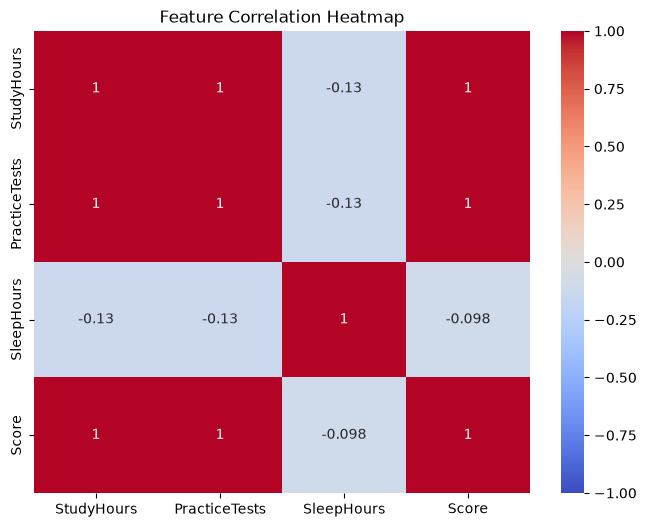

               StudyHours  PracticeTests  SleepHours     Score
StudyHours       1.000000       1.000000   -0.130931  0.998464
PracticeTests    1.000000       1.000000   -0.130931  0.998464
SleepHours      -0.130931      -0.130931    1.000000 -0.098399
Score            0.998464       0.998464   -0.098399  1.000000


In [6]:
correlation_df = pd.DataFrame({
    "StudyHours": [1, 2, 3, 4, 5, 6],
    "PracticeTests": [2, 4, 6, 8, 10, 12],
    "SleepHours": [8, 7, 8, 6, 7, 8],
    "Score": [45, 50, 58, 65, 72, 80]
})

corr_matrix = correlation_df.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.title("Feature Correlation Heatmap")
plt.show()

print(corr_matrix)

## Result / Observation

The heatmap displays the direction and strength of linear relationships.

StudyHours and PracticeTests are perfectly correlated in this illustrative dataset, so they contain overlapping information.

A real selection decision should be made on training data and checked against validation performance.

# 7. Variance Threshold


## Step 1 – Understand Concept

Variance measures how much numerical values vary around their mean.

A feature with zero variance has the same value in every row.

A near-constant feature changes very little across the dataset.

Variance Threshold removes features whose variance is below a specified threshold.

It is a simple, unsupervised method because it does not use the target variable.

Important limitations:
- A low-variance feature may still be important.
- Variance depends on the feature's scale.
- For binary features, variance depends on the proportion of each class.
- Scale or encode features appropriately before applying a threshold where needed.



## Step 2 – Demonstrate Concept

Consider:

ConstantFeature = [5, 5, 5, 5, 5]

ChangingFeature = [1, 3, 5, 7, 9]

The constant feature has zero variance.

The changing feature has positive variance.

The constant feature usually provides no information for distinguishing observations.




## Step 3 – Implement the Concept

In [7]:
from sklearn.feature_selection import VarianceThreshold

variance_df = pd.DataFrame({
    "ConstantFeature": [5, 5, 5, 5, 5],
    "AlmostConstant": [1, 1, 1, 1, 2],
    "ChangingFeature": [1, 3, 5, 7, 9]
})

selector = VarianceThreshold(threshold=0)

selected_array = selector.fit_transform(variance_df)

selected_columns = variance_df.columns[
    selector.get_support()
]

print("Original columns:", list(variance_df.columns))
print("Selected columns:", list(selected_columns))
print("Variances:")
print(variance_df.var())

Original columns: ['ConstantFeature', 'AlmostConstant', 'ChangingFeature']
Selected columns: ['AlmostConstant', 'ChangingFeature']
Variances:
ConstantFeature     0.0
AlmostConstant      0.2
ChangingFeature    10.0
dtype: float64


## Result / Observation

VarianceThreshold with threshold=0 removes the constant feature.

The almost-constant feature remains because it has nonzero variance.

The threshold should be selected carefully. Removing a feature based only on low variance can discard useful information.

# 8. Univariate Feature Selection


## Step 1 – Understand Concept

Univariate feature selection evaluates each feature individually in relation to the target.

It uses a statistical test or scoring function to rank features.

Examples include:
- SelectKBest
- SelectPercentile
- F-test for classification or regression
- Chi-square for suitable non-negative categorical/count representations

Advantages:
- Simple to understand.
- Fast for many datasets.
- Useful for initial feature screening.

Limitations:
- It may miss interactions between features.
- A feature that is weak alone may be useful with another feature.
- The score depends on the chosen statistical test and data assumptions.



## Step 2 – Demonstrate Concept

Suppose we predict whether a student passes an exam.

Features:
- StudyHours
- PracticeTests
- FavouriteColour

A univariate method evaluates each feature separately against Pass.

If StudyHours has a strong statistical relationship with Pass, it may receive a higher score.

This does not automatically prove it will be the best feature in every model.



## Step 3 – Implement the Concept

In [8]:
from sklearn.feature_selection import SelectKBest, f_classif

X_student = pd.DataFrame({
    "StudyHours": [1, 2, 3, 4, 5, 6, 7, 8],
    "PracticeTests": [1, 1, 2, 2, 3, 3, 4, 4],
    "FavouriteColourCode": [1, 3, 2, 1, 3, 2, 1, 3]
})

y_student = np.array([0, 0, 0, 1, 1, 1, 1, 1])

selector = SelectKBest(
    score_func=f_classif,
    k=2
)

X_student_selected = selector.fit_transform(
    X_student,
    y_student
)

selected_features = X_student.columns[
    selector.get_support()
]

print("Selected features:", list(selected_features))
print("Feature scores:", selector.scores_)

Selected features: ['StudyHours', 'PracticeTests']
Feature scores: [15.         11.30769231  0.        ]


## Result / Observation

SelectKBest selected the two features with the highest scores under the chosen statistical test.

This example is illustrative and small, so the scores should not be treated as reliable evidence for a real model.

For a real ML workflow, fit feature selection on training data only and evaluate the selected features using validation or cross-validation.

# 9. Mutual Information


## Step 1 – Understand Concept

Mutual Information measures how much knowing one variable reduces uncertainty about another.

For feature selection, it measures the statistical dependence between an input feature and the target.

Unlike simple Pearson correlation, mutual information can detect some nonlinear relationships.

Important limitations:
- A high score does not prove causation.
- Scores can be affected by sample size and estimation settings.
- It evaluates individual features and may miss interactions.
- It requires the correct scoring function for classification or regression.



## Step 2 – Demonstrate Concept

Suppose a target depends on a feature in a curved, nonlinear way.

Pearson correlation may be close to zero even though the feature contains useful information.

Mutual information may detect this dependence.

This makes mutual information useful when a feature's relationship with the target is not necessarily linear.




## Step 3 – Implement the Concept

In [9]:
from sklearn.feature_selection import mutual_info_classif

X_mi = pd.DataFrame({
    "UsefulFeature": [0, 1, 2, 3, 4, 5, 6, 7],
    "NoiseFeature": [3, 7, 1, 6, 2, 5, 0, 4]
})

y_mi = np.array([0, 1, 0, 1, 0, 1, 0, 1])

mi_scores = mutual_info_classif(
    X_mi,
    y_mi,
    random_state=42
)

mi_results = pd.Series(
    mi_scores,
    index=X_mi.columns
).sort_values(ascending=False)

print(mi_results)

NoiseFeature     0.480357
UsefulFeature    0.000000
dtype: float64


## Result / Observation

The scores rank the features according to estimated statistical dependence with the target.

Mutual information can identify nonlinear dependence, but a high score does not guarantee improved model performance.

Use sufficient data and validate the feature-selection results.

# 10. Recursive Feature Elimination (RFE)


## Step 1 – Understand Concept

Recursive Feature Elimination (RFE) is a wrapper-based feature-selection method.

It works by:

1. Training a model using the available features.
2. Ranking features using the model's importance or coefficients.
3. Removing the least important feature or features.
4. Training the model again.
5. Repeating until the required number of features remains.

Advantages:
- Considers the selected model's behaviour.
- Can select a specified number of features.

Limitations:
- More computationally expensive than simple filters.
- Results depend on the estimator.
- Can be unstable when features are strongly correlated.
- The number of selected features needs to be chosen appropriately.


## Step 2 – Demonstrate Concept

Suppose we have ten candidate features and want to keep four.

RFE trains a model and repeatedly removes the least important features according to that model.

The process continues until four features remain.

RFE is different from selecting features using correlation alone because it repeatedly evaluates features through a chosen estimator.



## Step 3 – Implement the Concept

In [10]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

X_rfe = pd.DataFrame({
    "Tenure": [2, 5, 12, 24, 36, 48, 3, 9, 30, 42],
    "MonthlyCharges": [80, 75, 70, 65, 60, 55, 90, 85, 62, 58],
    "ContractMonths": [1, 1, 12, 12, 24, 24, 1, 1, 24, 24],
    "RandomFeature": [5, 2, 8, 1, 9, 3, 7, 4, 6, 0]
})

y_rfe = np.array([1, 1, 1, 0, 0, 0, 1, 1, 0, 0])

# RFE uses Logistic Regression as its estimator.
# Scaling is included so the coefficients are learned from
# features on comparable scales.
rfe = RFE(
    estimator=LogisticRegression(max_iter=1000),
    n_features_to_select=2
)

rfe_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("selector", rfe)
])

rfe_pipeline.fit(X_rfe, y_rfe)

selected_features = X_rfe.columns[
    rfe.support_
]

ranking = pd.Series(
    rfe.ranking_,
    index=X_rfe.columns
).sort_values()

print("Selected features:", list(selected_features))
print("\nFeature rankings:")
print(ranking)

Selected features: ['Tenure', 'MonthlyCharges']

Feature rankings:
Tenure            1
MonthlyCharges    1
ContractMonths    2
RandomFeature     3
dtype: int64


## Result / Observation

RFE selected two features using Logistic Regression as its estimator.

A ranking of 1 indicates a selected feature. Larger ranks indicate features eliminated earlier.

This is a demonstration with a very small synthetic dataset. In real projects, use a training split and validate the selected feature set through cross-validation.

# 11. Feature Importance


## Step 1 – Understand Concept

Feature importance describes how useful individual features are according to a particular model or importance method.

Common approaches include:

- Tree-based feature importance
- Model coefficients
- Permutation importance

Tree-based models can estimate importance based on how features contribute to tree splits.

Permutation importance measures how much a model's evaluation score changes when a feature's values are shuffled.

Important limitations:
- Importance depends on the model and dataset.
- Correlated features can share or hide importance.
- Tree-based importance can favour certain feature types or split opportunities.
- Importance does not prove causation.
- Coefficient magnitudes should not be compared blindly when features have different scales.


## Step 2 – Demonstrate Concept

Suppose a model predicts customer churn.

The model may assign high importance to ContractMonths and Tenure.

A random identifier may receive low importance if it does not help the model.

We can inspect importance scores to understand the model's behaviour.

However, a low importance score in one model does not prove a feature is useless for every model.



## Step 3 – Implement the Concept

MonthlyCharges    0.414167
Tenure            0.406905
ContractMonths    0.172500
RandomFeature     0.006429
dtype: float64


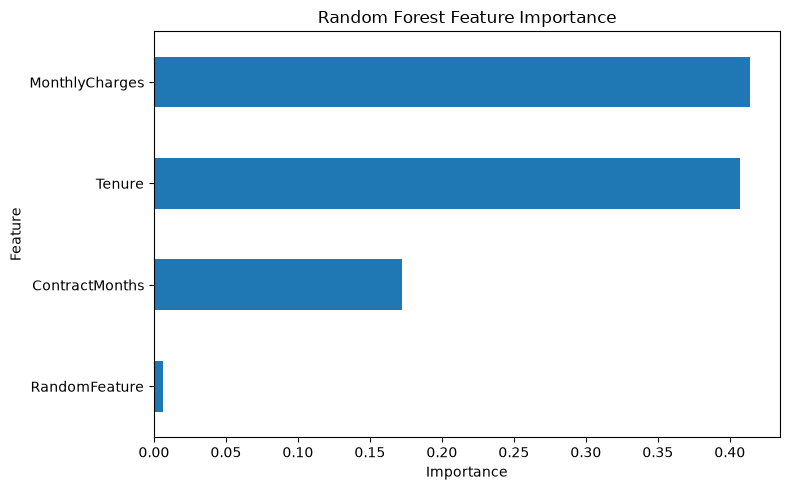

In [11]:
from sklearn.ensemble import RandomForestClassifier

importance_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

importance_model.fit(X_rfe, y_rfe)

importance = pd.Series(
    importance_model.feature_importances_,
    index=X_rfe.columns
).sort_values(ascending=False)

print(importance)

importance.sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## Result / Observation

The chart ranks features according to the Random Forest's impurity-based importance.

These values describe how the model used the features in this small example.

They do not show whether a feature causes churn, and the rankings may change with different data or models.

For stronger conclusions, evaluate features on held-out data and consider permutation importance.

# 12. How Unnecessary Features Affect Machine Learning Models


## Step 1 – Understand Concept

Unnecessary features can affect Machine Learning in several ways.

1. Increased computation:
   More features can require more memory and training time.

2. Overfitting:
   Noisy features can encourage a model to learn patterns that do not generalize.

3. Reduced interpretability:
   It becomes harder to explain which inputs matter.

4. Distance distortion:
   In distance-based algorithms such as KNN, irrelevant features can distort distances.

5. Multicollinearity:
   Redundant features can make some linear-model coefficients unstable or harder to interpret.

6. Data collection cost:
   Unnecessary features may require additional time, money, or system resources.

7. Reduced generalization:
   If the model learns accidental relationships, performance on unseen data may suffer.

These effects are not guaranteed. Some models handle irrelevant features reasonably well, and removing features can sometimes reduce performance.



## Step 2 – Demonstrate Concept

Imagine predicting customer churn using:

- Tenure
- MonthlyCharges
- ContractMonths
- A random number
- A unique row identifier

The first three features may contain meaningful customer information.

The random number and row identifier may add complexity without useful predictive value.

For KNN, irrelevant numerical columns can change distances between customers.

For linear models, redundant columns may make coefficients difficult to interpret.

Therefore, we should evaluate whether removing unnecessary features improves validation performance and simplifies the model.



## Step 3 – Implement the Concept

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

comparison_df = pd.DataFrame({
    "Tenure": [2, 5, 12, 24, 36, 48, 3, 9, 30, 42,
               6, 18, 27, 40, 4, 33, 14, 46, 21, 38],
    "MonthlyCharges": [80, 75, 70, 65, 60, 55, 90, 85, 62, 58,
                       88, 72, 68, 57, 91, 61, 78, 54, 69, 59],
    "ContractMonths": [1, 1, 12, 12, 24, 24, 1, 1, 24, 24,
                       1, 12, 12, 24, 1, 24, 12, 24, 12, 24],
    "RandomFeature": [5, 2, 8, 1, 9, 3, 7, 4, 6, 0,
                      9, 1, 5, 8, 2, 7, 3, 6, 0, 4],
    "Churn": [1, 1, 1, 0, 0, 0, 1, 1, 0, 0,
              1, 1, 0, 0, 1, 0, 1, 0, 1, 0]
})

X_all = comparison_df.drop(columns="Churn")
y_all = comparison_df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X_all,
    y_all,
    test_size=0.3,
    random_state=42,
    stratify=y_all
)

# Compare all features with a reduced set.
# Keep the same split for a fair comparison.
selected_columns = [
    "Tenure",
    "MonthlyCharges",
    "ContractMonths"
]

model_all = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=3)
)

model_selected = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=3)
)

model_all.fit(X_train, y_train)

model_selected.fit(
    X_train[selected_columns],
    y_train
)

pred_all = model_all.predict(X_test)

pred_selected = model_selected.predict(
    X_test[selected_columns]
)

print(
    "Accuracy with all features:",
    accuracy_score(y_test, pred_all)
)

print(
    "Accuracy with selected features:",
    accuracy_score(y_test, pred_selected)
)

Accuracy with all features: 1.0
Accuracy with selected features: 0.5


## Result / Observation

The code compares a KNN model using all features with one using three selected features.

Both models use the same train/test split, and scaling is fitted separately within each training pipeline.

The test accuracy may be higher, lower, or unchanged after feature selection.

This small synthetic example is for demonstrating the process only. Reliable conclusions require a larger representative dataset and suitable validation.

Feature selection is useful when it improves generalization, efficiency, interpretability, or data collection cost without sacrificing necessary predictive information.

# 13. Safe Feature Selection Workflow


## Step 1 – Understand Concept

Feature selection must be performed carefully to avoid data leakage.

A safe workflow is:

1. Identify the target variable.
2. Remove features that are clearly invalid or unavailable at prediction time.
3. Split the data into training, validation, and test sets as appropriate.
4. Fit data-dependent feature-selection methods on training data only.
5. Use validation or cross-validation to select the approach.
6. Evaluate the final workflow on untouched test data.
7. Document the reasons for keeping or removing features.

Do not use test-set target information to select features.

Any data-dependent feature-selection method should be fitted within the training process.




## Step 2 – Demonstrate Concept

Incorrect workflow:

Use the entire dataset and target labels to select features.
Then split the selected dataset into train and test.

This allows test-set information to influence feature selection.

Correct workflow:

Split first.
Fit feature selection on training data.
Apply the fitted selector to validation/test data.
Evaluate the model on data that did not influence feature selection.



## Step 3 – Implement the Concept

In [13]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

safe_pipeline = Pipeline([
    ("feature_selection", SelectKBest(
        score_func=f_classif,
        k=2
    )),
    ("scaling", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

# The pipeline fits feature selection and scaling
# using only the training data.
safe_pipeline.fit(X_train, y_train)

test_predictions = safe_pipeline.predict(X_test)

print(
    "Test accuracy:",
    accuracy_score(y_test, test_predictions)
)

Test accuracy: 0.8333333333333334


## Result / Observation

The pipeline fits the feature selector and scaler during model training.

When predicting on test data, the already-fitted transformations are applied without learning from the test labels.

This helps prevent feature-selection leakage and provides a more trustworthy evaluation.

# Final Summary – Feature Selection

In this notebook, we learned:

1. What is Feature Selection?
2. Why Feature Selection?
3. Relevant Features
4. Irrelevant Features
5. Redundant Features
6. Correlation-Based Selection
7. Variance Threshold
8. Univariate Feature Selection
9. Mutual Information
10. Recursive Feature Elimination
11. Feature Importance
12. How Unnecessary Features Affect Machine Learning Models
13. Safe Feature Selection Workflow

## Key Differences

- Correlation-based selection: investigates linear relationships.
- Variance Threshold: removes low-variance features without using the target.
- Univariate selection: scores features individually against the target.
- Mutual Information: measures statistical dependence, including some nonlinear relationships.
- RFE: repeatedly eliminates features using a chosen estimator.
- Feature Importance: estimates the usefulness of features according to a model or importance method.

## Important Rule

Do not remove features simply because they look unnecessary.

Investigate their meaning, examine relationships, fit selection methods on training data, and evaluate the impact on unseen data.